In [3]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression 
from sklearn.ensemble import RandomForestClassifier
from imblearn.under_sampling import RandomUnderSampler
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve, precision_recall_curve, classification_report, ConfusionMatrixDisplay
import shap 

In [4]:
pd.set_option('display.max_columns', None)
path = r"C:\Users\Data Professor\Downloads\revenueGaurd AI\transactions.csv"

In [5]:
raw_data = pd.read_csv(path)

print(raw_data.head())

  transaction_id  transaction_value  customer_tenure_months customer_type  \
0      RG0000001           30593.35                      83           SME   
1      RG0000002           11159.11                      79    Individual   
2      RG0000003           42737.77                      48    Individual   
3      RG0000004           49287.39                      93    Individual   
4      RG0000005            5634.84                      88    Individual   

  sales_channel payment_method  payment_terms_days  discount_rate_pct  \
0        Direct           Card                  30               8.58   
1        Mobile  Bank Transfer                  14               5.49   
2        Mobile   Direct Debit                  30              32.24   
3        Online  Bank Transfer                   7               9.75   
4        Mobile   Direct Debit                  30               9.96   

   manual_discount_flag  approval_delay_hours  invoice_delay_days  \
0                     1      

In [6]:
raw_data.duplicated().any()

np.False_

In [7]:
raw_data.isna().any()

transaction_id                           False
transaction_value                        False
customer_tenure_months                   False
customer_type                            False
sales_channel                            False
payment_method                           False
payment_terms_days                       False
discount_rate_pct                        False
manual_discount_flag                     False
approval_delay_hours                     False
invoice_delay_days                       False
order_complexity_score                   False
service_completion_pct                   False
delivery_delay_days                      False
prior_customer_disputes                  False
prior_payment_defaults                   False
billing_adjustment_count                 False
reconciliation_frequency_days            False
system_integration_score                 False
operational_exception_count              False
contract_compliance_score                False
revenue_leaka

In [8]:
df = raw_data.copy()

In [9]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 24 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   transaction_id                         6000 non-null   object 
 1   transaction_value                      6000 non-null   float64
 2   customer_tenure_months                 6000 non-null   int64  
 3   customer_type                          6000 non-null   object 
 4   sales_channel                          6000 non-null   object 
 5   payment_method                         6000 non-null   object 
 6   payment_terms_days                     6000 non-null   int64  
 7   discount_rate_pct                      6000 non-null   float64
 8   manual_discount_flag                   6000 non-null   int64  
 9   approval_delay_hours                   6000 non-null   float64
 10  invoice_delay_days                     6000 non-null   float64
 11  orde

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
transaction_value,6000.0,32097.044010,28006.597015,905.21000,14605.805000,24496.740000,39364.807500,324660.34000
customer_tenure_months,6000.0,60.331833,34.645554,1.00000,31.000000,60.000000,90.000000,120.00000
payment_terms_days,6000.0,26.366333,17.673790,0.00000,14.000000,30.000000,30.000000,60.00000
discount_rate_pct,6000.0,10.879763,6.759997,0.02000,5.677500,9.740000,14.772500,43.63000
manual_discount_flag,6000.0,0.175167,0.380141,0.00000,0.000000,0.000000,0.000000,1.00000
approval_delay_hours,6000.0,9.041742,6.781386,0.04000,4.120000,7.300000,12.210000,48.91000
invoice_delay_days,6000.0,3.336080,2.773729,0.01000,1.320000,2.610000,4.570000,25.55000
order_complexity_score,6000.0,5.515667,2.890700,1.00000,3.000000,6.000000,8.000000,10.00000
service_completion_pct,6000.0,81.665007,11.861605,22.25000,74.547500,83.775000,90.970000,99.95000
delivery_delay_days,6000.0,2.339207,2.064052,0.01000,0.830000,1.780000,3.230000,19.40000


In [11]:
df.select_dtypes(include=['number']).corr()

,transaction_value,customer_tenure_months,payment_terms_days,discount_rate_pct,manual_discount_flag,approval_delay_hours,invoice_delay_days,order_complexity_score,service_completion_pct,delivery_delay_days,prior_customer_disputes,prior_payment_defaults,billing_adjustment_count,reconciliation_frequency_days,system_integration_score,operational_exception_count,contract_compliance_score,revenue_leakage_probability_reference,revenue_leakage,leakage_amount
transaction_value,1.000000,-0.023133,-0.007403,-0.001496,0.006480,0.007605,0.009426,0.004381,0.012995,0.006099,-0.002707,-0.006125,-0.002455,0.024892,0.022181,0.024553,-0.005922,0.009721,-0.000106,0.344220
customer_tenure_months,-0.023133,1.000000,0.001054,-0.017758,-0.000199,0.005393,0.002633,0.000150,0.004540,-0.016098,0.003455,0.002270,0.013277,0.011265,-0.000637,0.016557,0.001060,-0.091195,-0.023996,-0.024576
payment_terms_days,-0.007403,0.001054,1.000000,-0.005717,-0.000149,-0.015989,0.007312,0.002553,0.002425,0.001260,-0.018526,0.004627,-0.003919,0.015949,-0.007340,-0.006535,0.009488,0.001469,0.019234,0.015687
discount_rate_pct,-0.001496,-0.017758,-0.005717,1.000000,-0.000896,-0.007541,-0.013952,-0.002552,-0.003276,0.001693,-0.020434,-0.021606,-0.019603,-0.007368,0.004106,-0.001116,0.009316,0.106107,0.050445,0.066031
manual_discount_flag,0.006480,-0.000199,-0.000149,-0.000896,1.000000,0.009369,0.003476,0.009410,0.029224,0.013617,0.006315,0.006106,0.012686,-0.016931,-0.003350,-0.017973,0.001209,0.321053,0.113506,0.091118
approval_delay_hours,0.007605,0.005393,-0.015989,-0.007541,0.009369,1.000000,-0.008246,0.014108,-0.000685,0.030403,-0.010099,-0.011128,0.014409,-0.027442,0.006712,0.017491,0.011775,0.153973,0.058340,0.040318
invoice_delay_days,0.009426,0.002633,0.007312,-0.013952,0.003476,-0.008246,1.000000,-0.007868,-0.010065,0.004734,0.008312,0.021056,0.022391,-0.010388,0.013763,0.017436,0.011301,0.492660,0.179931,0.131212
order_complexity_score,0.004381,0.000150,0.002553,-0.002552,0.009410,0.014108,-0.007868,1.000000,0.016486,0.010305,0.005251,0.005099,-0.011915,-0.011703,-0.029668,-0.030156,0.005078,0.297804,0.098421,0.051519
service_completion_pct,0.012995,0.004540,0.002425,-0.003276,0.029224,-0.000685,-0.010065,0.016486,1.000000,-0.015834,-0.003426,0.023497,0.016965,-0.026939,0.006428,0.004678,-0.004795,0.006211,0.009189,0.006396
delivery_delay_days,0.006099,-0.016098,0.001260,0.001693,0.013617,0.030403,0.004734,0.010305,-0.015834,1.000000,0.016627,0.019124,-0.008644,0.005592,0.015281,-0.004702,-0.000725,0.280591,0.111699,0.077403


In [12]:
df.columns

Index(['transaction_id', 'transaction_value', 'customer_tenure_months',
       'customer_type', 'sales_channel', 'payment_method',
       'payment_terms_days', 'discount_rate_pct', 'manual_discount_flag',
       'approval_delay_hours', 'invoice_delay_days', 'order_complexity_score',
       'service_completion_pct', 'delivery_delay_days',
       'prior_customer_disputes', 'prior_payment_defaults',
       'billing_adjustment_count', 'reconciliation_frequency_days',
       'system_integration_score', 'operational_exception_count',
       'contract_compliance_score', 'revenue_leakage_probability_reference',
       'revenue_leakage', 'leakage_amount'],
      dtype='object')

In [13]:
x = df.drop(['transaction_id','revenue_leakage_probability_reference','revenue_leakage', 'leakage_amount' ], axis = 1)
y = df.revenue_leakage

In [14]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=42)

In [15]:

rus = RandomUnderSampler(random_state=42)
x_train_bal, y_train_bal = rus.fit_resample(x_train, y_train)

# Keep y as a Series carrying the original column name
y_train_bal = pd.Series(y_train_bal, name=y_train.name)

print("Training class counts before undersampling:")
print(y_train.value_counts())
print("\nTraining class counts after undersampling:")
print(y_train_bal.value_counts())

Training class counts before undersampling:
revenue_leakage
0    3196
1    1304
Name: count, dtype: int64

Training class counts after undersampling:
revenue_leakage
0    1304
1    1304
Name: count, dtype: int64


In [16]:
def process_data(dat):
    dat = dat.copy()

    num_cols = dat.select_dtypes(include=['number']).columns
    cat_cols = dat.select_dtypes(include=['object']).columns

    num_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    cat_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value = -1))
    ])

    preprocessor = ColumnTransformer([
        ('num', num_pipe, num_cols),
        ('cat', cat_pipe, cat_cols)
    ],
    remainder = 'passthrough'
    )
    return preprocessor

process_data(x_train)


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``.

In [17]:
# Create preprocessing pipeline using training features
processor = process_data(x_train)

# Random Forest Pipeline
rf_pipeline = Pipeline([
    ('preprocessor', processor),
    ('classifier', RandomForestClassifier(random_state=42))
])

rf_pipeline.fit(x_train, y_train)

rf_predict = rf_pipeline.predict(x_test)



y_prob = rf_pipeline.predict_proba(x_test)[:, 1]

thresholds = np.arange(0.05, 0.81, 0.05)

results = []

for threshold in thresholds:

    y_pred = (y_prob >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Leakage_Precision": precision_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "Leakage_Recall": recall_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "Leakage_F1": f1_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "No_Leakage_Recall": recall_score(
            y_test, y_pred, pos_label=0, zero_division=0
        ),
        "Predicted_Leakage": int((y_pred == 1).sum())
    })

threshold_results = pd.DataFrame(results)

threshold_results = threshold_results.sort_values(
    by="Leakage_Recall",
    ascending=False
)

threshold_results.round(3)


,Threshold,Accuracy,Leakage_Precision,Leakage_Recall,Leakage_F1,No_Leakage_Recall,Predicted_Leakage
0,0.05,0.269,0.269,1.000,0.424,0.000,1500
1,0.10,0.285,0.271,0.980,0.425,0.028,1461
2,0.15,0.342,0.280,0.921,0.430,0.129,1327
3,0.20,0.421,0.301,0.869,0.447,0.255,1167
4,0.25,0.547,0.351,0.800,0.488,0.454,921
5,0.30,0.623,0.385,0.666,0.488,0.608,699
6,0.35,0.683,0.425,0.498,0.458,0.752,473
7,0.40,0.716,0.467,0.389,0.424,0.837,336
8,0.45,0.739,0.533,0.262,0.352,0.915,199
9,0.50,0.738,0.550,0.151,0.237,0.954,111


Classification Report — Random Forest
              precision    recall  f1-score   support

           0       0.79      0.03      0.05      1096
           1       0.27      0.98      0.42       404

    accuracy                           0.28      1500
   macro avg       0.53      0.50      0.24      1500
weighted avg       0.65      0.28      0.15      1500

Confusion Matrix — Random Forest
[[  31 1065]
 [   8  396]]


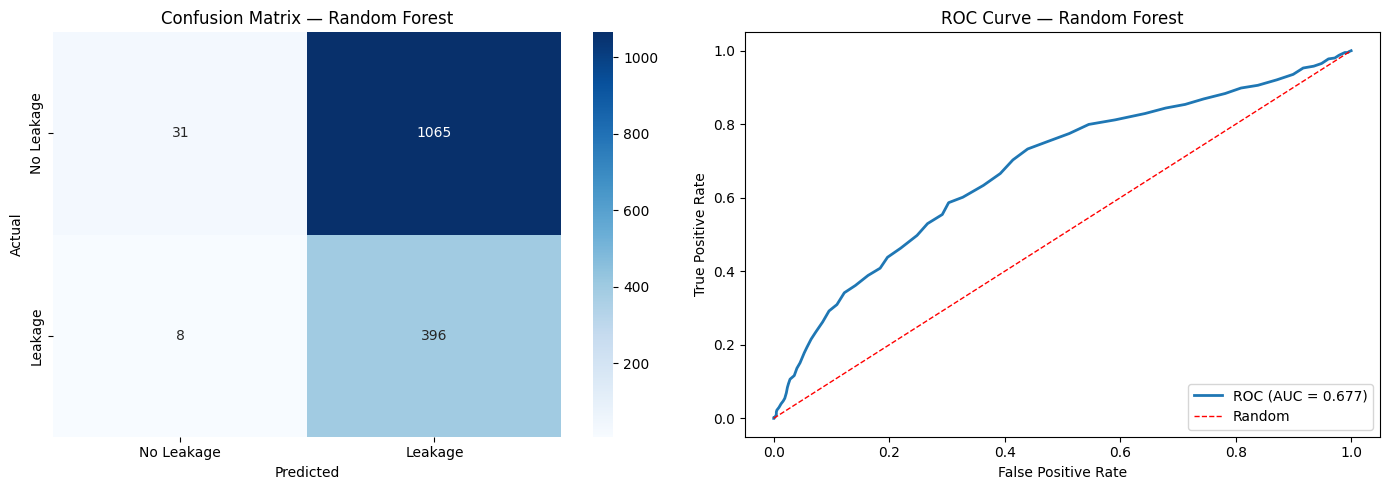

In [18]:
def evaluate_model(model, x_test, y_test, model_name='Model', threshold=0.5):
    """
    Prints classification report, plots confusion matrix and ROC/AUC curve.
    """
    y_proba = model.predict_proba(x_test)[:, 1]
    y_pred = (y_proba >= threshold).astype(int)

    # Classification Report
    print(f"{'=' * 40}")
    print(f"Classification Report — {model_name}")
    print(f"{'=' * 40}")
    print(classification_report(y_test, y_pred))

    # Confusion Matrix + ROC Curve side-by-side
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)

    print(f"{'=' * 40}")
    print(f"Confusion Matrix — {model_name}")
    print(cm)
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
                xticklabels=['No Leakage', 'Leakage'],
                yticklabels=['No Leakage', 'Leakage'])
    axes[0].set_title(f'Confusion Matrix — {model_name}')
    axes[0].set_xlabel('Predicted')
    axes[0].set_ylabel('Actual')

    # ROC Curve / AUC
    if hasattr(model, 'predict_proba'):
        y_proba = model.predict_proba(x_test)[:, 1]
    elif hasattr(model, 'decision_function'):
        y_proba = model.decision_function(x_test)
    else:
        y_proba = y_pred

    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = roc_auc_score(y_test, y_proba)

    axes[1].plot(fpr, tpr, lw=2, label=f'ROC (AUC = {roc_auc:.3f})')
    axes[1].plot([0, 1], [0, 1], 'r--', lw=1, label='Random')
    axes[1].set_title(f'ROC Curve — {model_name}')
    axes[1].set_xlabel('False Positive Rate')
    axes[1].set_ylabel('True Positive Rate')
    axes[1].legend(loc='lower right')

    plt.tight_layout()
    plt.show()


evaluate_model(rf_pipeline, x_test, y_test, 'Random Forest', threshold=0.10)

Classification Report — Logistic Regression
              precision    recall  f1-score   support

           0       0.90      0.05      0.09      1096
           1       0.28      0.99      0.43       404

    accuracy                           0.30      1500
   macro avg       0.59      0.52      0.26      1500
weighted avg       0.73      0.30      0.18      1500

Confusion Matrix — Logistic Regression
[[  52 1044]
 [   6  398]]


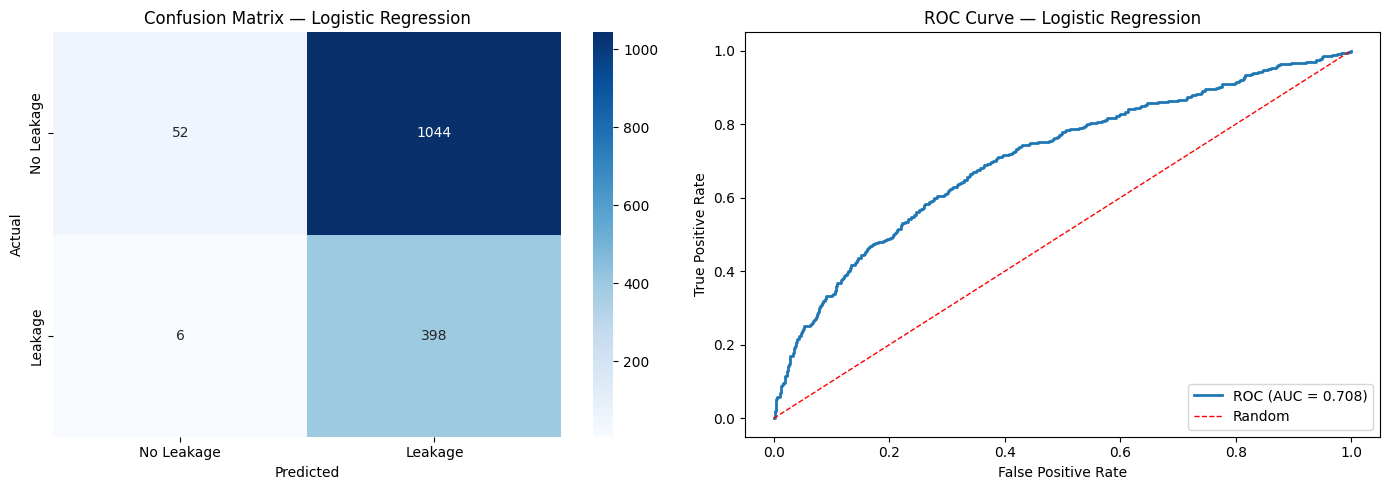

In [19]:
# Logistic Regression Pipeline
lr_pipeline = Pipeline([
    ('preprocessor', processor),
    ('classifier', LogisticRegression(random_state=42))
])

lr_pipeline.fit(x_train, y_train)

lr_predict = lr_pipeline.predict(x_test)



lr_y_prob = lr_pipeline.predict_proba(x_test)[:, 1]

lr_thresholds = np.arange(0.05, 0.81, 0.05)

lr_results = []

for threshold in lr_thresholds:

    lr_y_pred = (lr_y_prob >= threshold).astype(int)

    lr_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, lr_y_pred),
        "Leakage_Precision": precision_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "Leakage_Recall": recall_score(
            y_test, lr_y_pred, pos_label=1, zero_division=0
        ),
        "Leakage_F1": f1_score(
            y_test, lr_y_pred, pos_label=1, zero_division=0
        ),
        "No_Leakage_Recall": recall_score(
            y_test, lr_y_pred, pos_label=0, zero_division=0
        ),
        "Predicted_Leakage": int((lr_y_pred == 1).sum())
    })

lr_threshold_results = pd.DataFrame(lr_results)

lr_threshold_results = lr_threshold_results.sort_values(
    by="Leakage_Recall",
    ascending=False
)

lr_threshold_results.round(3)


evaluate_model(lr_pipeline, x_test, y_test, 'Logistic Regression', threshold=0.10)


In [20]:
# Extract fitted components
preprocessor = lr_pipeline.named_steps['preprocessor']

lr_model = lr_pipeline.named_steps['classifier']

# Inspect model coefficients
print("Model coefficients:", lr_model.coef_.shape)
print("Model intercept:", lr_model.intercept_)

Model coefficients: (1, 20)
Model intercept: [-0.88406427]


In [21]:
# Transform datasets
X_train_transformed = preprocessor.transform(x_train)

X_test_transformed = preprocessor.transform(x_test)

# Convert sparse matrices to dense arrays if necessary
if hasattr(X_train_transformed, "toarray"):
    X_train_transformed = X_train_transformed.toarray()

if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()

# Extract transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Convert to DataFrames
X_train_shap = pd.DataFrame(
    X_train_transformed,
    columns=feature_names,
    index=x_train.index
)

X_test_shap = pd.DataFrame(
    X_test_transformed,
    columns=feature_names,
    index=x_test.index
)

print("Training shape:", X_train_shap.shape)
print("Testing shape:", X_test_shap.shape)

Training shape: (4500, 20)
Testing shape: (1500, 20)


In [22]:
# Select background dataset
background = shap.sample(
    X_train_shap,
    min(100, len(X_train_shap)),
    random_state=42
)

# Initialise SHAP Linear Explainer
explainer = shap.LinearExplainer(
    lr_model,
    background
)

# Generate SHAP values
shap_values = explainer(
    X_test_shap
)

print("SHAP values generated successfully!")

SHAP values generated successfully!


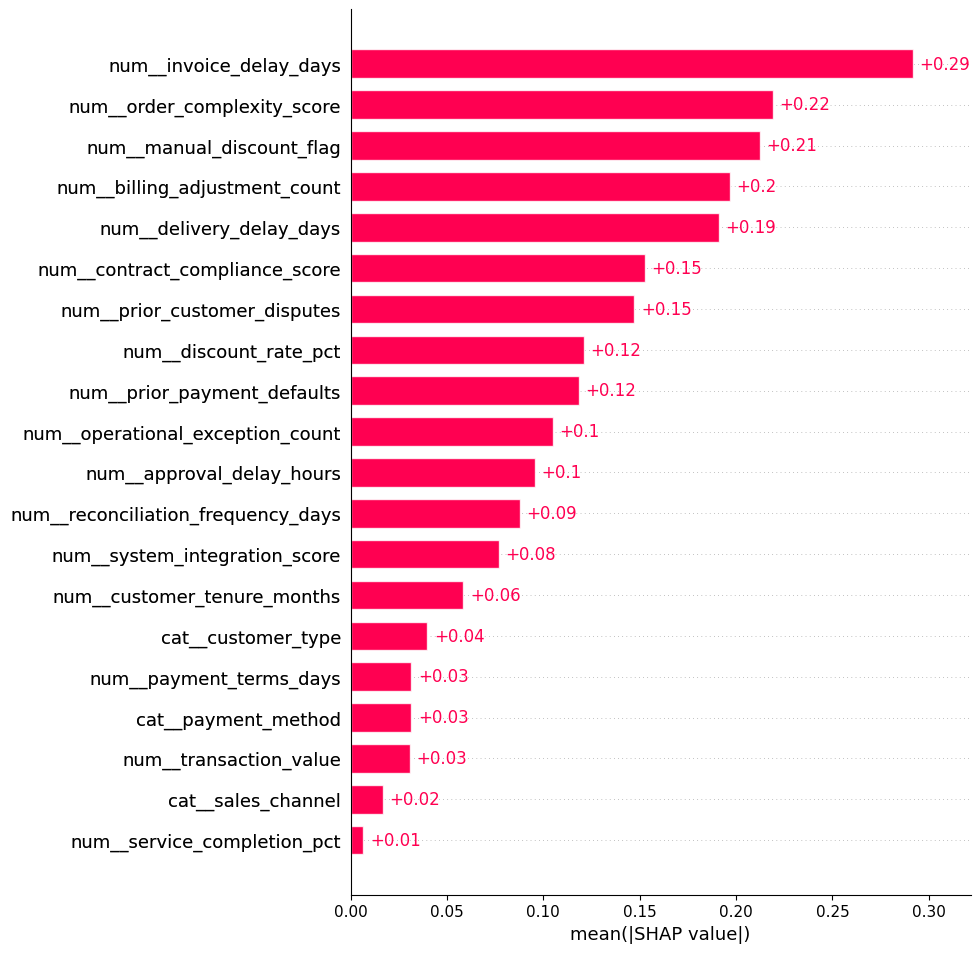

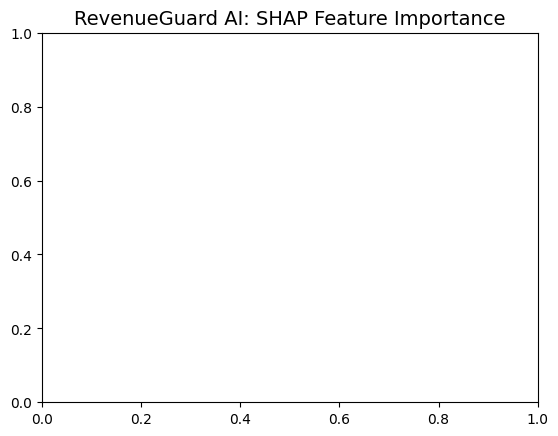

In [23]:
# Global feature importance
shap.plots.bar(
    shap_values,
    max_display=20
)

plt.title(
    "RevenueGuard AI: SHAP Feature Importance",
    fontsize=14
)

plt.show()

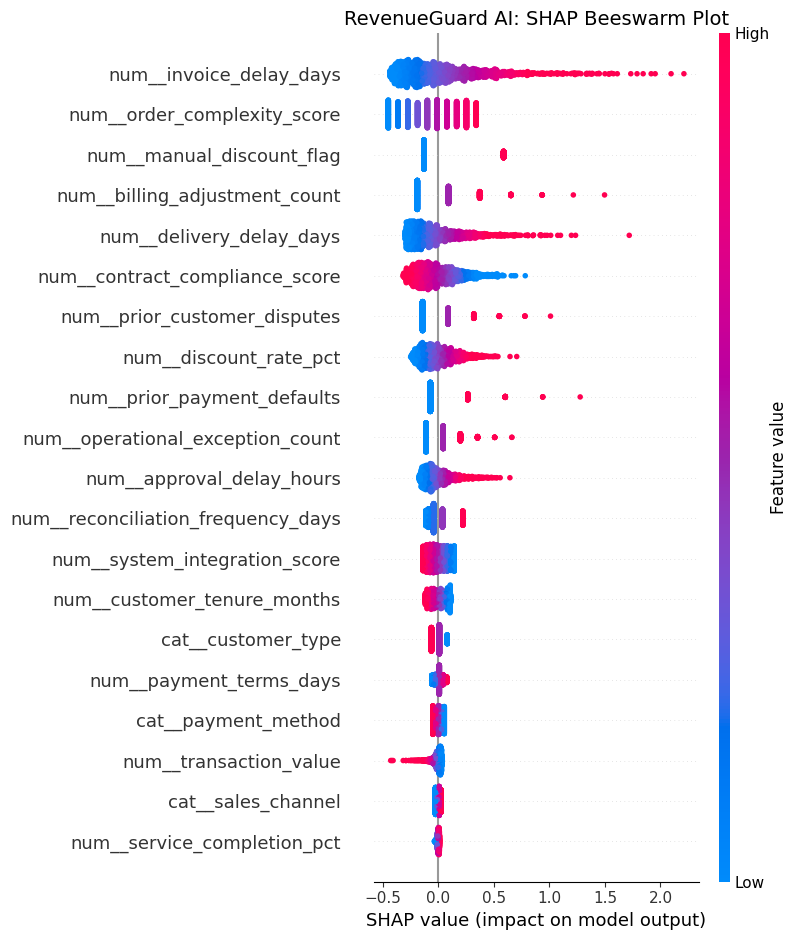

In [24]:
plt.figure(figsize=(12, 8))

shap.plots.beeswarm(
    shap_values,
    max_display=20,
    show=False
)

plt.title(
    "RevenueGuard AI: SHAP Beeswarm Plot",
    fontsize=14
)

plt.tight_layout()
plt.show()

Selected observation: 73
Actual class: 1
Predicted leakage probability: 0.8432


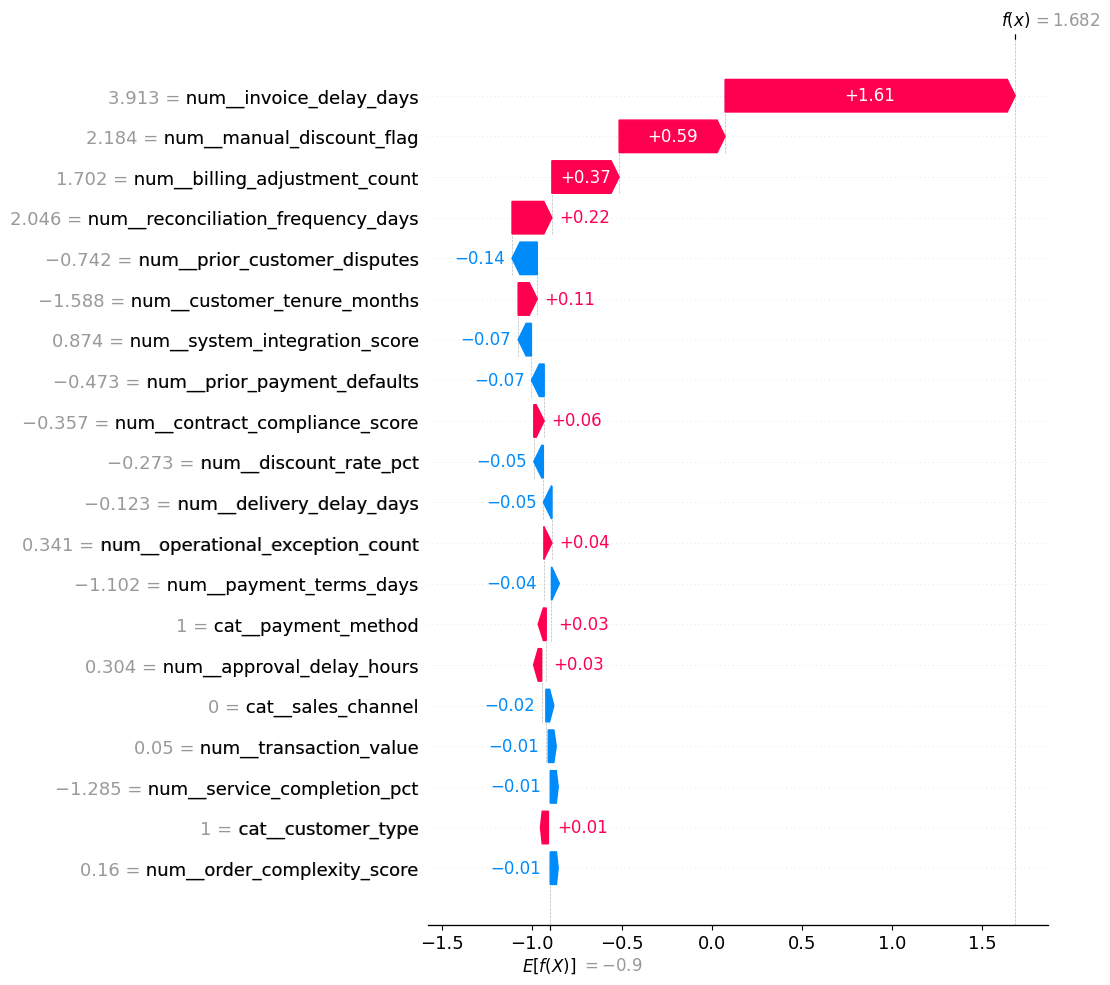

In [25]:
# Find test observations where actual leakage occurred
leakage_indices = np.where(
    np.asarray(y_test) == 1
)[0]

# Get predicted Class 1 probabilities
lr_probabilities = lr_pipeline.predict_proba(x_test)[:, 1]

# Select the actual leakage case with the highest predicted probability
selected_index = leakage_indices[
    np.argmax(lr_probabilities[leakage_indices])
]

print("Selected observation:", selected_index)

print(
    "Actual class:",
    np.asarray(y_test)[selected_index]
)

print(
    "Predicted leakage probability:",
    round(lr_probabilities[selected_index], 4)
)

# Generate waterfall plot
shap.plots.waterfall(
    shap_values[selected_index],
    max_display=20
)

In [26]:

import joblib
import os


# Create model directory
os.makedirs("models", exist_ok=True)

# Save the complete fitted pipeline
joblib.dump(
    lr_pipeline,
    "models/revenueguard_logistic_pipeline.joblib"
)

print("Logistic Regression pipeline saved successfully!")


Logistic Regression trained successfully!
Logistic Regression pipeline saved successfully!
